# On-Device Voice Agent — Windows Jupyter Runner

Runs the **RQ2 latency-split** experiment on native Windows. Two Windows-specific
choices make this work without the errors you hit:

1. **`llama-cpp-python` via prebuilt CPU wheel** — skips the source build that
   fails on Windows' 260-char path limit.
2. **TTS via `pyttsx3` (SAPI5)** — Windows' built-in speech engine; no flaky
   Piper phonemizer wheels.

> **Note:** for the *paper's* numbers you'll ultimately want Linux/WSL (the claim
> is about Linux commodity CPU). Windows is fine for development + first results.

Run cells top to bottom. Cells 2-3 are one-time.

## 1. Point the kernel at the repo root

In [1]:
import os, sys
if os.path.basename(os.getcwd()).lower() == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
print('cwd:', os.getcwd())
assert os.path.isdir('src'), 'run from project root (should see src/)'
print('ok')

cwd: d:\personal\research
ok


## 2. Install (Windows-safe)
Prebuilt llama wheel + SAPI5 TTS. If pip warns about the wheel index, see the
fallback note at the bottom.

In [2]:
import sys
PY = sys.executable
print('Python:', sys.version)   # wheel must match this (CPython 3.10-3.13)
# light deps
!"{PY}" -m pip install -q -r requirements.txt
# llama-cpp-python: PREBUILT CPU wheel ONLY. --only-binary :all: FORBIDS the
# source build (which hits Windows' 260-char long-path limit). If no wheel
# matches your Python, this errors cleanly instead of trying to compile.
!"{PY}" -m pip install llama-cpp-python --only-binary :all: --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu
# ASR + Windows-native TTS + audio IO
!"{PY}" -m pip install -q faster-whisper soundfile pyttsx3
print('install step done — check above for any red errors')

Python: 3.13.14 | packaged by Anaconda, Inc. | (main, Jun 17 2026, 20:04:52) [MSC v.1942 64 bit (AMD64)]
Looking in indexes: https://pypi.org/simple, https://abetlen.github.io/llama-cpp-python/whl/cpu
install step done — check above for any red errors


## 3. Download one small model (~2 GB) + select Windows TTS

In [3]:
import os
from huggingface_hub import hf_hub_download
os.makedirs('models', exist_ok=True)

llm_path = hf_hub_download(
    repo_id='bartowski/Qwen2.5-3B-Instruct-GGUF',
    filename='Qwen2.5-3B-Instruct-Q4_K_M.gguf', local_dir='models')
print('LLM:', llm_path)

# Use Windows SAPI5 TTS (no Piper) and a small fast whisper.
os.environ['VA_TTS_BACKEND'] = 'pyttsx3'
os.environ['VA_ASR_MODEL'] = 'base'
os.environ['VA_ASR_COMPUTE'] = 'int8'
print('TTS backend: pyttsx3 (SAPI5)')

c:\Users\Sakthivinash.B\AppData\Local\anaconda3\envs\automation\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LLM: D:\personal\research\models\Qwen2.5-3B-Instruct-Q4_K_M.gguf
TTS backend: pyttsx3 (SAPI5)


## 4. Sanity check — dummy run (instant)

In [4]:
from importlib import reload
import src.experiments.rq2_latency as rq2
reload(rq2)
rq2.run(dummy=True, quant='dummy', model_path=None, n_turns=3)


=== RQ2 latency breakdown [dummy] (n=3) ===
  asr_s          mean=  100.9 ms  p95=  101.1 ms
  llm_decode_s   mean=  608.3 ms  p95=  610.2 ms
  tts_total_s    mean=  267.1 ms  p95=  270.4 ms
  total_s        mean=  976.5 ms
  TTFT           mean=  221.3 ms
  TTFA           mean=  325.7 ms

  -> DOMINANT STAGE: llm_decode_s (62% of stage time)
     Consistent with our hypothesis (LLM-dominated), contra 'TTS dominates'.
  -> Mean TTFA 326 ms vs 1000 ms 'broken' budget: WITHIN budget.


## 5. Real RQ2 on your Windows CPU
First call loads the model + downloads whisper `base` (~1 min one-time).

In [5]:
import src.experiments.rq2_latency as rq2
reload(rq2)
rq2.run(dummy=False, quant='Q4_K_M',
        model_path=r'models/Qwen2.5-3B-Instruct-Q4_K_M.gguf', n_turns=5)

llama_context: n_ctx_seq (4096) < n_ctx_train (32768) -- the full capacity of the model will not be utilized



=== RQ2 latency breakdown [Q4_K_M] (n=5) ===
  asr_s          mean= 1521.5 ms  p95= 1892.9 ms
  llm_decode_s   mean= 6524.7 ms  p95= 9554.3 ms
  tts_total_s    mean=  220.1 ms  p95=  250.7 ms
  total_s        mean= 8276.8 ms
  TTFT           mean= 2021.0 ms
  TTFA           mean= 2086.9 ms

  -> DOMINANT STAGE: llm_decode_s (79% of stage time)
     Consistent with our hypothesis (LLM-dominated), contra 'TTS dominates'.
  -> Mean TTFA 2087 ms vs 1000 ms 'broken' budget: OVER budget.


## 6. Plot the latency split — your draft Figure 1

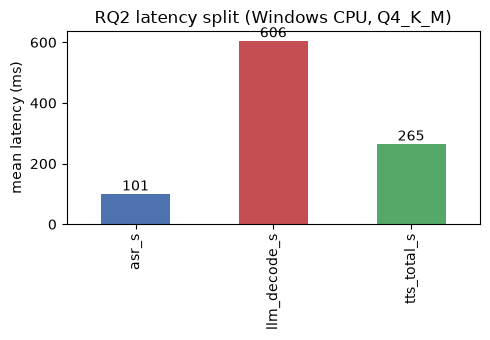

Dominant: llm_decode_s (62% of stage time)
LLM-dominated -> confirms hypothesis, contra refuted "TTS dominates".


In [6]:
import pandas as pd, matplotlib.pyplot as plt, glob
f = sorted(glob.glob('results/rq2_latency_*.jsonl'))[-1]
df = pd.read_json(f, lines=True)
m = df[['asr_s','llm_decode_s','tts_total_s']].mean() * 1000
ax = m.plot.bar(color=['#4C72B0','#C44E52','#55A868'], figsize=(5,3.5))
ax.set_ylabel('mean latency (ms)'); ax.set_title('RQ2 latency split (Windows CPU, Q4_K_M)')
for i,v in enumerate(m): ax.text(i, v, f'{v:.0f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()
dom = m.idxmax()
print(f'Dominant: {dom} ({m[dom]/m.sum()*100:.0f}% of stage time)')
print('LLM-dominated -> confirms hypothesis, contra refuted "TTS dominates".'
      if dom=='llm_decode_s' else 'Surprise -- investigate.')

## Troubleshooting (Windows)
- **`llama-cpp-python` still tries to build / long-path error:** the prebuilt
  wheel index in cell 2 should prevent this. If it persists, enable Windows long
  paths (admin PowerShell): `New-ItemProperty -Path 'HKLM:\SYSTEM\CurrentControlSet\Control\FileSystem' -Name LongPathsEnabled -Value 1 -PropertyType DWORD -Force`, then reopen the terminal.
- **No wheel for your Python version:** prebuilt wheels lag new Python releases.
  Use Python 3.10-3.12, or `pip install llama-cpp-python` after `pip install cmake`
  + installing Visual Studio Build Tools (C++).
- **`pyttsx3` import error / no `pywin32`:** `pip install pywin32 pyttsx3`.
- **TTFA on Windows is approximate** (SAPI5 doesn't stream) — fine for the
  LLM-vs-TTS dominance question; `tts_total_s` is measured exactly.
- **Caveat for the paper:** report Windows numbers as development/sanity only;
  the headline CPU results should come from Linux/WSL.